In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt 
import statsmodels.api as sm 
from statsmodels.tsa.stattools import adfuller, acf
from statsmodels.stats.diagnostic import acorr_ljungbox 
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
warnings.filterwarnings("ignore", category=FutureWarning) # keep library deprecation notices out of class
plt.rcParams["figure.figsize"] = (11, 3.4)

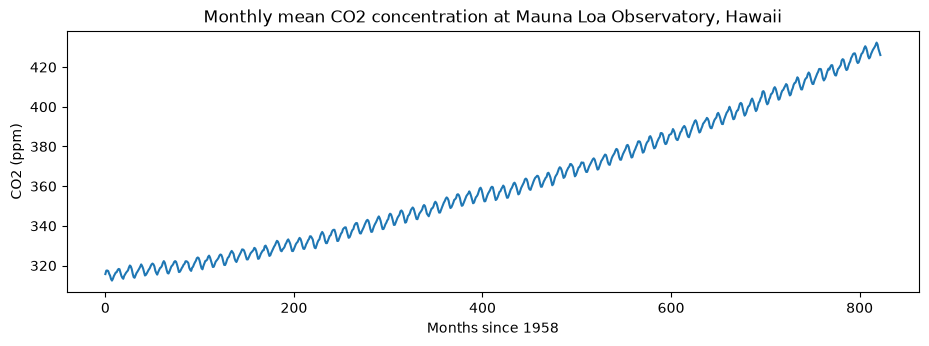

In [3]:
URL= "https://gml.noaa.gov/webdata/ccgg/trends/co2/co2_mm_mlo.csv"
raw= pd.read_csv(URL, comment="#")
co2=raw['average']
co2.plot(title='Monthly mean CO2 concentration at Mauna Loa Observatory, Hawaii', ylabel='CO2 (ppm)', xlabel='Months since 1958')
plt.show()

In [4]:
raw.tail()

,year,month,decimal date,average,deseasonalized,ndays,sdev,unc
818,2026,5,2026.3750,432.34,429.05,19,0.64,0.28
819,2026,6,2026.4583,431.43,429.00,19,0.27,0.12
820,2026,7,2026.5417,429.13,428.74,21,0.61,0.26
821,2026,8,2026.6250,427.55,429.48,17,0.38,0.18
822,2026,9,2026.7083,426.07,429.55,18,0.51,0.23


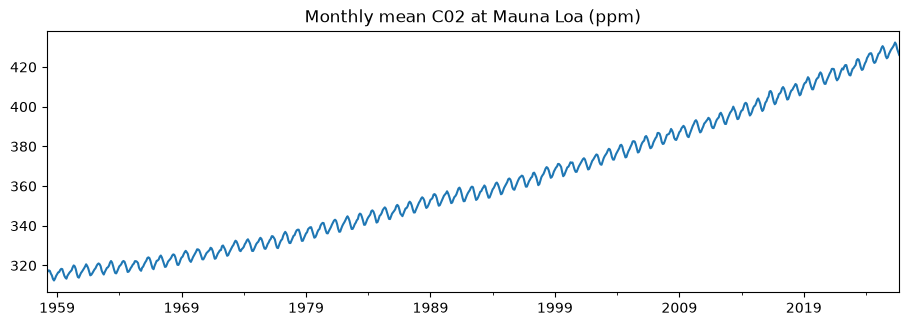

In [5]:
raw.index = pd.to_datetime(raw[["year", "month"]].assign(day=1))
raw= raw.asfreq('MS') # set the frequency to monthly start
co2=raw['average']
co2.plot(title="Monthly mean C02 at Mauna Loa (ppm)")
plt.show()

In [8]:
train=co2.loc["1974-01":"2025-12"]
test= co2.loc["2026-01":"2026-12"]
print(len(train), "training months,", len(test), "test months")
raw.loc["1975":"2025"].query("sdev < 0")[["average","ndays", "sdev"]]

624 training months, 9 test months


,average,ndays,sdev
1975-12-01,330.77,-1,-9.99
1984-04-01,347.37,2,-9.99


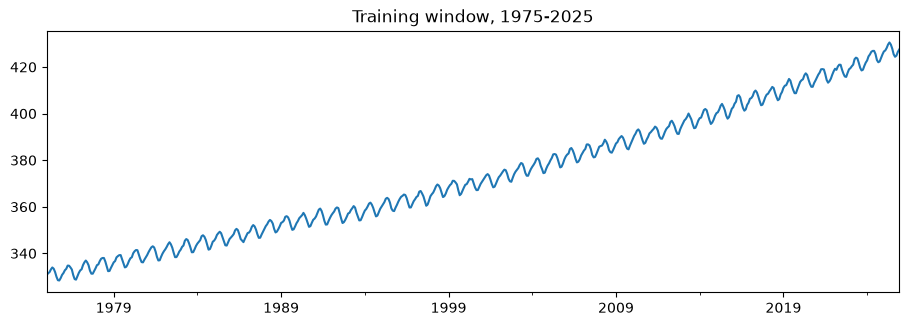

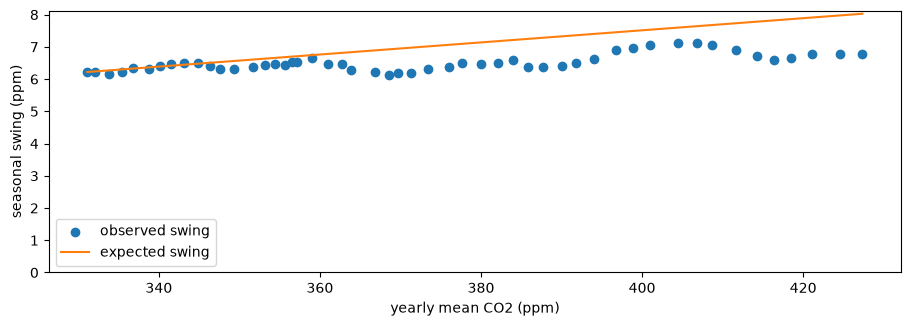

level (1975-2025): 331.1 -> 427.3 ppm (96.2 ppm increase)


In [10]:
import pandas as pd

train_window = train.loc["1975":"2025"]
train_window.plot(
    title=f"Training window, {train_window.index.min().year}-{train_window.index.max().year}"
)
plt.show()

seasonal = (raw["average"] - raw["deseasonalized"]).loc["1975":"2025"]
swingc = seasonal.groupby(seasonal.index.year).agg(lambda x: x.max() - x.min())
level = train_window.groupby(train_window.index.year).mean()

# Alinear ambas series por año y eliminar valores faltantes.
annual = pd.concat(
    [level.rename("level"), swingc.rename("swing")],
    axis=1,
    join="inner",
).dropna().sort_index()

if annual.empty:
    raise ValueError("No hay años comunes con datos válidos.")

first_year = annual.index[0]
last_year = annual.index[-1]
first_level = annual.loc[first_year, "level"]
last_level = annual.loc[last_year, "level"]

plt.scatter(annual["level"], annual["swing"], label="observed swing")
plt.plot(
    annual["level"],
    annual.loc[first_year, "swing"] * annual["level"] / first_level,
    color="C1",
    label="expected swing",
)
plt.ylim(0, None)
plt.xlabel("yearly mean CO2 (ppm)")
plt.ylabel("seasonal swing (ppm)")
plt.legend()
plt.show()

print(
    f"level ({first_year}-{last_year}): "
    f"{first_level:.1f} -> {last_level:.1f} ppm "
    f"({last_level - first_level:.1f} ppm increase)"
)

ADF, Z: p= 0.000


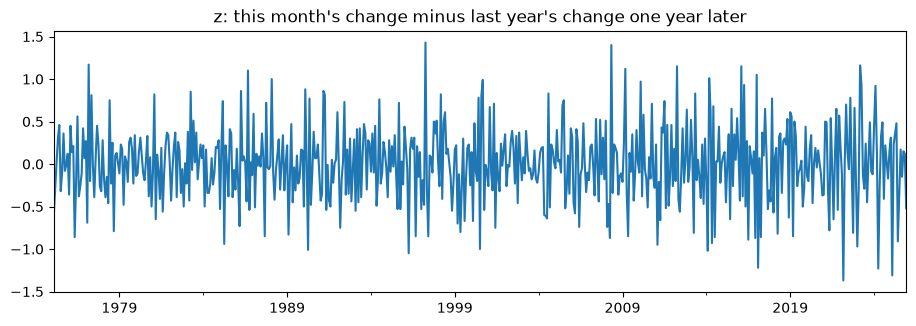

In [11]:
z = train.diff().diff(12).dropna()
print("ADF, Z: p=", f"{adfuller(z)[1]:.3f}")
z.plot(title="z: this month's change minus last year's change one year later")
plt.show()

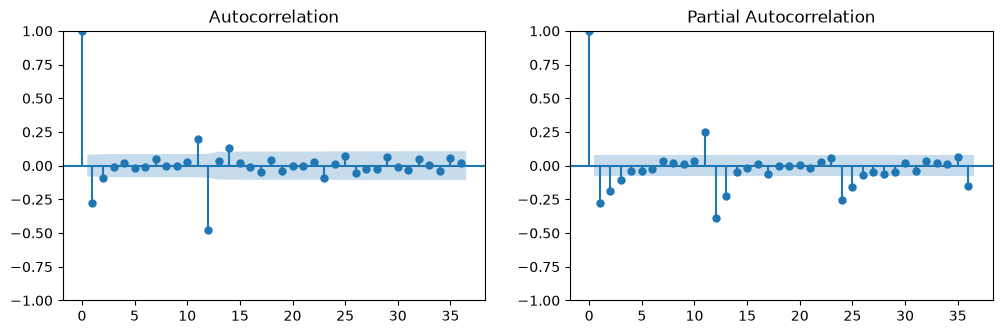

1    -0.28
2    -0.09
3    -0.01
11    0.19
12   -0.48
13    0.03
14    0.13
24    0.01
36    0.02
dtype: float64

In [12]:
fig, ax =plt.subplots(1,2,figsize=(12,3.5))
plot_acf(z, lags=36, ax=ax[0])
plot_pacf(z, lags=36, ax=ax[1])
plt.show()

acf_z = acf(z,nlags=36)
lags = [1,2,3,11,12,13,14,24,36]
pd.Series(acf_z[lags], index=lags).round(2)

In [13]:
fit = sm.tsa.SARIMAX(train, order=(0,1,1), seasonal_order=(1,1,1,12)).fit(disp=False)
print(fit.summary().tables[1])
theta, Theta = fit.params["ma.L1"], fit.params["ar.S.L12"]
print("ACF the model predicts at lags 11 and 13:", round(Theta*theta / ((1+theta**2)*(1+Theta**2) *(1+Theta**2)), 2))
print("ACF in the data at lags 11 and 13:", round(acf_z[11], 2), round(acf_z[13], 2))

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ma.L1         -0.4104      0.035    -11.883      0.000      -0.478      -0.343
ar.S.L12       0.0229      0.047      0.492      0.623      -0.068       0.114
ma.S.L12      -0.8877      0.025    -35.003      0.000      -0.937      -0.838
sigma2         0.0984      0.005     19.698      0.000       0.089       0.108
ACF the model predicts at lags 11 and 13: -0.01
ACF in the data at lags 11 and 13: 0.19 0.03


In [18]:
candidates = {
    "airline (0,1,1)(0,1,1)":((0, 1, 1), (0, 1, 1, 12)),
    "+ A(1)": ((1, 1, 1), (0, 1, 1, 12)),
    "+ MA(2), q=w": ((0, 1, 2), (0, 1, 1, 12)),
    "+ seasonal AR(1)": ((0, 1, 1), (1, 1, 1, 12)),
    "AR version (1,1,0)(0,1,1)": ((1, 1, 0), (0, 1, 1, 12)),
}
rows = []
for name, (order, seasonal_order) in candidates.items():
    f = sm.tsa.SARIMAX(train, order=order, seasonal_order=seasonal_order).fit(disp=False)
    k = len(f.params)-1
    lb_p=acorr_ljungbox(f.resid.iloc[13:], lags=[24], model_df=k)["lb_pvalue"].iloc[0]
    rows.append({"model": name, "AIC": round(f.aic, 2), "BIC": round(f.bic, 2), "Ljung-Box p": round(lb_p, 4)})
pd.DataFrame(rows).sort_values("BIC")

,model,AIC,BIC,Ljung-Box p
0,"airline (0,1,1)(0,1,1)",341.63,354.88,0.8061
2,"+ MA(2), q=w",340.23,357.89,0.9124
1,+ A(1),340.29,357.95,0.9100
3,+ seasonal AR(1),343.38,361.04,0.7344
4,"AR version (1,1,0)(0,1,1)",363.25,376.50,0.0368
